In [1]:
from pathlib import Path
ROOT = Path("../..").resolve()

import joblib
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
# Đánh giá
from sklearn.metrics import (
    classification_report, 
    f1_score, 
    recall_score, 
    precision_score, 
    roc_auc_score, 
    average_precision_score,
    precision_recall_curve,
    confusion_matrix
)

# Đường dẫn đến thư mục chứa dữ liệu đã xử lý
DATA_PATH = ROOT / 'src/data/processed'

In [2]:
from sklearn.metrics import log_loss
import shap

def sample_xy(X, y, max_samples=30000, random_state=42):
    if len(y) <= max_samples:
        return X, np.asarray(y)

    rng = np.random.default_rng(random_state)
    idx = np.sort(rng.choice(len(y), size=max_samples, replace=False))

    if hasattr(X, "iloc"):
        X_sample = X.iloc[idx].copy()
    else:
        X_sample = X[idx]

    y_array = np.asarray(y)
    return X_sample, y_array[idx]


def build_checkpoints(total_steps, max_points=60):
    if total_steps <= max_points:
        return list(range(1, total_steps + 1))

    checkpoints = np.linspace(1, total_steps, num=max_points, dtype=int)
    return sorted(set(int(step) for step in checkpoints))


def plot_loss_curve(loss_df, title):
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(loss_df["step"], loss_df["train_loss"], marker="o", markersize=3, linewidth=2, label="Train LogLoss")
    ax.plot(loss_df["step"], loss_df["test_loss"], marker="o", markersize=3, linewidth=2, label="Test LogLoss")
    ax.set_title(title)
    ax.set_xlabel("Iteration / Trees")
    ax.set_ylabel("LogLoss")
    ax.grid(alpha=0.25)
    ax.legend()
    plt.tight_layout()
    plt.show()

    display(loss_df.tail(10))


def extract_shap_values(shap_output):
    if isinstance(shap_output, list):
        return shap_output[1] if len(shap_output) > 1 else shap_output[0]

    values = shap_output.values if hasattr(shap_output, "values") else shap_output
    if isinstance(values, np.ndarray) and values.ndim == 3:
        return values[:, :, 1] if values.shape[2] > 1 else values[:, :, 0]

    return values


def plot_shap_test(model, X_test, model_name, sample_size=2000, max_display=20, random_state=42):
    if hasattr(X_test, "sample"):
        X_sample = X_test.sample(min(sample_size, len(X_test)), random_state=random_state).copy()
    else:
        rng = np.random.default_rng(random_state)
        idx = np.sort(rng.choice(len(X_test), size=min(sample_size, len(X_test)), replace=False))
        X_sample = X_test[idx]

    try:
        explainer = shap.TreeExplainer(model)
        shap_output = explainer.shap_values(X_sample)
    except Exception:
        explainer = shap.Explainer(model, X_sample)
        shap_output = explainer(X_sample)

    shap_values = extract_shap_values(shap_output)
    feature_names = X_sample.columns.tolist() if hasattr(X_sample, 'columns') else feature_cols
    shap.summary_plot(shap_values, X_sample, feature_names=feature_names, show=False, max_display=max_display)
    plt.title(f"SHAP Summary - {model_name} (Test Sample)")
    plt.tight_layout()
    plt.show()

    mean_abs_shap = np.abs(shap_values).mean(axis=0)
    shap_df = pd.DataFrame({
        "feature": X_sample.columns if hasattr(X_sample, "columns") else feature_cols,
        "mean_abs_shap": mean_abs_shap,
    }).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)

    print(f"Top {min(max_display, len(shap_df))} features by mean(|SHAP|) - {model_name}:")
    display(shap_df.head(max_display))


In [3]:
def load_data(path):
    X_train = joblib.load(os.path.join(path, 'X_train.pkl'))
    y_train = joblib.load(os.path.join(path, 'y_train.pkl'))
    X_test = joblib.load(os.path.join(path, 'X_test.pkl'))
    y_test = joblib.load(os.path.join(path, 'y_test.pkl'))
    X_val = joblib.load(os.path.join(path, 'X_val.pkl'))
    y_val = joblib.load(os.path.join(path, 'y_val.pkl'))
    feature_cols = joblib.load(os.path.join(path, 'feature_cols.pkl'))
    return X_train, y_train, X_test, y_test, X_val, y_val, feature_cols

X_train, y_train, X_test, y_test, X_val, y_val, feature_cols = load_data(DATA_PATH)
print(f" Train set: {X_train.shape}")
print(f" Test set: {X_test.shape}")
print(f" Validation set: {X_val.shape}")


 Train set: (416250, 28)
 Test set: (89197, 28)
 Validation set: (89196, 28)


## 1. Train Balanced Random Forest Classifier

`BalancedRandomForestClassifier` from `imbalanced-learn` handles class imbalance with random under-sampling of the majority class inside each bootstrap sample, so this notebook does not use SMOTE for BRF training.


In [4]:
from imblearn.ensemble import BalancedRandomForestClassifier

# Initialize the model
brf_model = BalancedRandomForestClassifier(
    n_estimators=1000,
    max_depth=6,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    sampling_strategy='auto',
    replacement=False,
    bootstrap=True,
    random_state=42,
    n_jobs=-1,
)

brf_model.fit(X_train, y_train)


BalancedRandomForestClassifier(bootstrap=True, max_depth=6, n_estimators=1000,
                               n_jobs=-1, random_state=42, replacement=False,
                               sampling_strategy='auto')

## 2. Baseline Evaluation

In [5]:
def calculate_metrics(y_true, y_pred, y_prob, label=""):
    metrics = {
        "F1": f1_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
    }
    if label:
        print(f"\n=== {label} ===")
        for k, v in metrics.items():
            print(f"  {k}: {v:.4f}")
    return metrics

# --- Baseline: đánh giá trên val set ---
brf_val_preds   = brf_model.predict(X_val)
brf_val_probs   = brf_model.predict_proba(X_val)[:, 1]


brf_baseline_val = calculate_metrics(y_val, brf_val_preds, brf_val_probs, "Balanced Random Forest Baseline – Val")


# --- Baseline: đánh giá trên test set ---
brf_test_preds  = brf_model.predict(X_test)
brf_test_probs  = brf_model.predict_proba(X_test)[:, 1]


brf_baseline_test = calculate_metrics(y_test, brf_test_preds, brf_test_probs, "Balanced Random Forest Baseline – Test")
# xgb_baseline_test = calculate_metrics(y_test, xgb_test_preds, xgb_test_probs, "XGBoost Baseline – Test")

# Bảng tóm tắt baseline
baseline_df = pd.DataFrame(
    [brf_baseline_val, brf_baseline_test],
    index=["Balanced Random Forest - Val", "Balanced Random Forest - Test"]
)
print("\nBaseline table:")
display(baseline_df.round(4))


=== Balanced Random Forest Baseline – Val ===
  F1: 0.5647
  Recall: 0.9928
  Precision: 0.3945
  ROC-AUC: 0.9981
  PR-AUC: 0.8730

=== Balanced Random Forest Baseline – Test ===
  F1: 0.5807
  Recall: 0.9854
  Precision: 0.4116
  ROC-AUC: 0.9979
  PR-AUC: 0.8580

Baseline table:


,F1,Recall,Precision,ROC-AUC,PR-AUC
Balanced Random Forest - Val,0.5647,0.9928,0.3945,0.9981,0.873
Balanced Random Forest - Test,0.5807,0.9854,0.4116,0.9979,0.858


## 3.Optuna - Tối ưu Hyperparameters  

In [6]:

def brf_objective(trial):
    params = {
        "n_estimators":     trial.suggest_int("n_estimators", 200, 2000),
        "max_depth":        trial.suggest_int("max_depth", 3, 12),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
        "min_samples_split":trial.suggest_int("min_samples_split", 2, 10),
        "max_features":     trial.suggest_categorical("max_features", ["sqrt", "log2"]),
        "random_state": 42,
        "n_jobs": -1,
        
    }
    model = BalancedRandomForestClassifier(**params)
    model.fit(X_train, y_train)
    probs = model.predict_proba(X_val)[:, 1]
    return average_precision_score(y_val, probs)

brf_study = optuna.create_study(direction="maximize", study_name="BalancedRandomForest-PRAUC")
brf_study.optimize(brf_objective, n_trials=45, show_progress_bar=True)

print(f"\nBalancedRandomForest best PR-AUC (val): {brf_study.best_value:.4f}")
print("Best params:", brf_study.best_params)

  0%|          | 0/45 [00:00<?, ?it/s]


BalancedRandomForest best PR-AUC (val): 0.9044
Best params: {'n_estimators': 1162, 'max_depth': 11, 'min_samples_leaf': 5, 'min_samples_split': 10, 'max_features': 'sqrt'}


# 4. Retrain with best params from Optuna


In [7]:
# --- Retrain BalancedRandomForest ---
brf_best = BalancedRandomForestClassifier(
    **brf_study.best_params,
    random_state=42,
    n_jobs=-1,
    bootstrap=True,

)
brf_best.fit(X_train, y_train)
print("BalancedRandomForest retrained with best params.")



BalancedRandomForest retrained with best params.


## 5. Đánh giá sau Optuna – So sánh trước/sau trên Val Set

In [8]:
# Đánh giá trên val set sau Optuna
brf_opt_val_preds = brf_best.predict(X_val)
brf_opt_val_probs = brf_best.predict_proba(X_val)[:, 1]


brf_opt_val = calculate_metrics(y_val, brf_opt_val_preds, brf_opt_val_probs, "BalancedRandomForest Optuna – Val")

# Bảng so sánh trước / sau Optuna trên Val Set
val_comparison = pd.DataFrame(
    [brf_baseline_val, brf_opt_val],
    index=["BalancedRandomForest - Baseline", "BalancedRandomForest - Optuna"]
)
print("\n Baseline vs Optuna (Val Set):")
display(val_comparison.round(4))

# Cáº£i thiá»‡n PR-AUC
brf_gain = brf_opt_val["PR-AUC"] - brf_baseline_val["PR-AUC"]
print(f"\nBalancedRandomForest PR-AUC gain: {brf_gain:+.4f}")


=== BalancedRandomForest Optuna – Val ===
  F1: 0.5843
  Recall: 0.9897
  Precision: 0.4145
  ROC-AUC: 0.9985
  PR-AUC: 0.8996

 Baseline vs Optuna (Val Set):


,F1,Recall,Precision,ROC-AUC,PR-AUC
BalancedRandomForest - Baseline,0.5647,0.9928,0.3945,0.9981,0.8730
BalancedRandomForest - Optuna,0.5843,0.9897,0.4145,0.9985,0.8996



BalancedRandomForest PR-AUC gain: +0.0266


## 6. Đánh giá cuối cùng trên Test Set (chạy 1 lần)

In [9]:
# Đánh giá trên test set (chỉ chạy 1 lần sau khi đã chốt model)
brf_opt_test_preds = brf_best.predict(X_test)
brf_opt_test_probs = brf_best.predict_proba(X_test)[:, 1]


brf_opt_test = calculate_metrics(y_test, brf_opt_test_preds, brf_opt_test_probs, "BalancedRandomForest Optuna – Test")

print("\nClassification Report – BalancedRandomForest Optuna (Test):")
print(classification_report(y_test, brf_opt_test_preds, target_names=["Non-fraud", "Fraud"]))


=== BalancedRandomForest Optuna – Test ===
  F1: 0.5974
  Recall: 0.9802
  Precision: 0.4296
  ROC-AUC: 0.9983
  PR-AUC: 0.8833

Classification Report – BalancedRandomForest Optuna (Test):
              precision    recall  f1-score   support

   Non-fraud       1.00      0.99      0.99     88235
       Fraud       0.43      0.98      0.60       962

    accuracy                           0.99     89197
   macro avg       0.71      0.98      0.80     89197
weighted avg       0.99      0.99      0.99     89197



## 7. Visualization – Confusion Matrix & Precision-Recall Curve (sau Optuna)

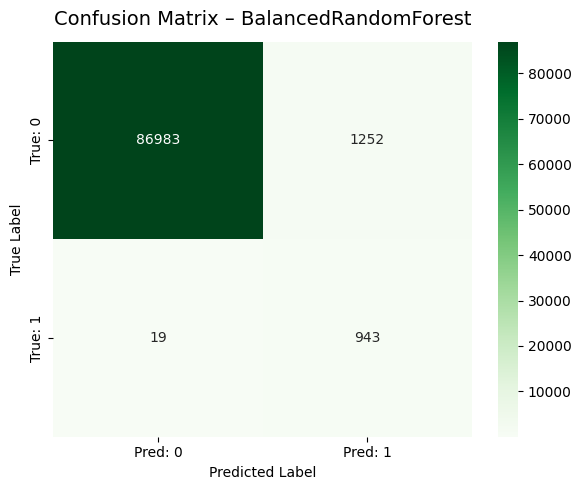

True Negatives  (TN): 86983
False Positives (FP): 1252
False Negatives (FN): 19
True Positives  (TP): 943


In [10]:
cm= confusion_matrix(y_test, brf_opt_test_preds)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Greens',
    xticklabels=['Pred: 0', 'Pred: 1'],
    yticklabels=['True: 0', 'True: 1'],
    ax=ax
)
ax.set_title('Confusion Matrix – BalancedRandomForest', fontsize=14, pad=12)
ax.set_xlabel('Predicted Label')
ax.set_ylabel('True Label')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives  (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives  (TP): {tp}")

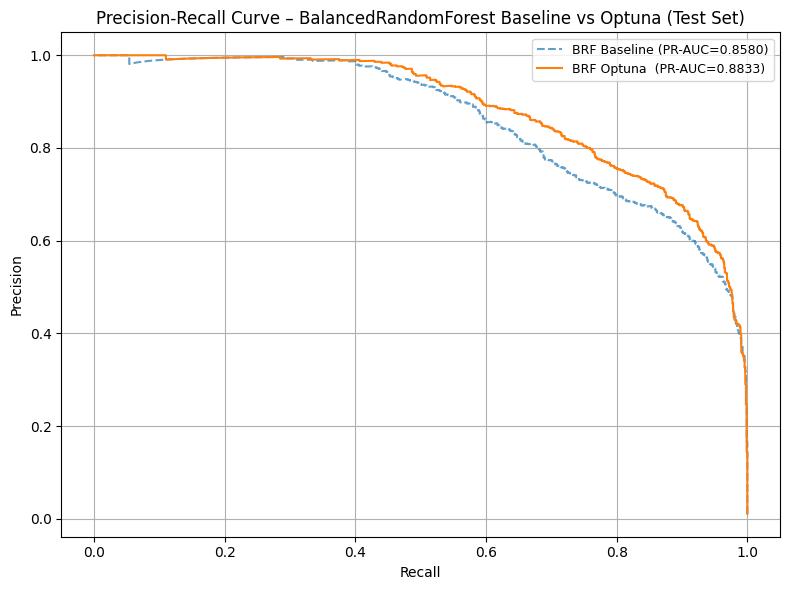

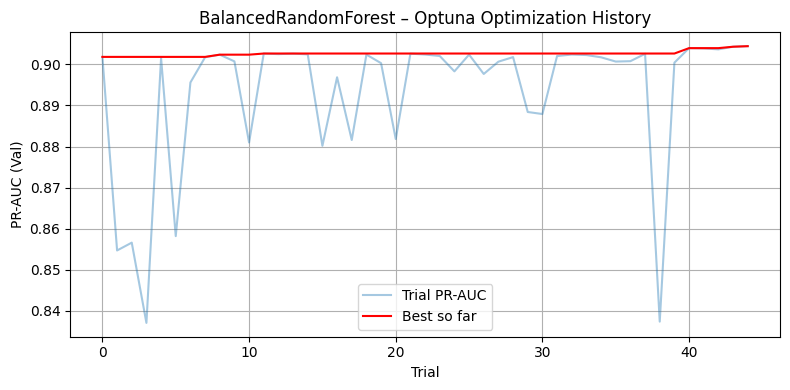

In [11]:
# Precision-Recall Curve – BalancedRandomForest Baseline vs Optuna
plt.figure(figsize=(8, 6))

prec_b, rec_b, _ = precision_recall_curve(y_test, brf_test_probs)
prec_o, rec_o, _ = precision_recall_curve(y_test, brf_opt_test_probs)
auc_b = average_precision_score(y_test, brf_test_probs)
auc_o = average_precision_score(y_test, brf_opt_test_probs)

plt.plot(rec_b, prec_b, linestyle="--", label=f"BRF Baseline (PR-AUC={auc_b:.4f})", alpha=0.7)
plt.plot(rec_o, prec_o, linestyle="-",  label=f"BRF Optuna  (PR-AUC={auc_o:.4f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve – BalancedRandomForest Baseline vs Optuna (Test Set)")
plt.legend(fontsize=9)
plt.grid(True)
plt.tight_layout()
plt.show()

# Optuna optimization history – BalancedRandomForest
plt.figure(figsize=(8, 4))
values = [t.value for t in brf_study.trials if t.value is not None]
best_so_far = pd.Series(values).cummax()
plt.plot(values, alpha=0.4, label="Trial PR-AUC")
plt.plot(best_so_far.values, color="red", label="Best so far")
plt.title("BalancedRandomForest – Optuna Optimization History")
plt.xlabel("Trial")
plt.ylabel("PR-AUC (Val)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 7. Loss Curve


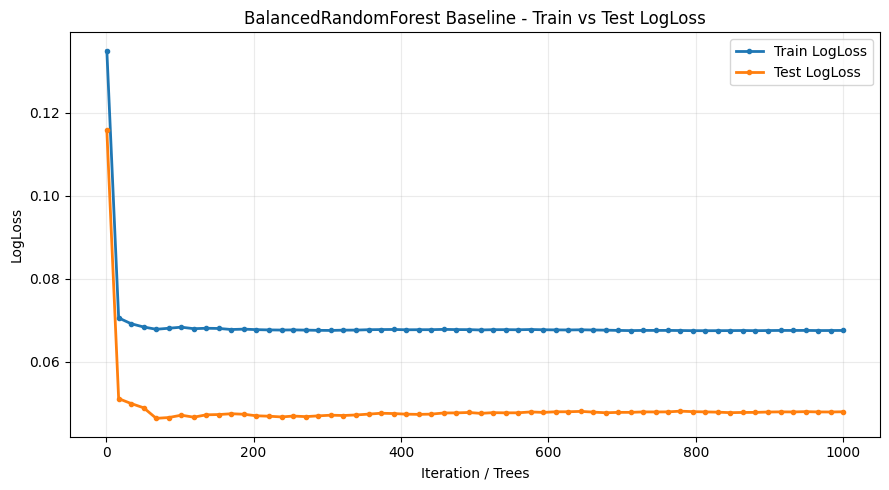

,step,train_loss,test_loss
50,847,0.067495,0.047722
51,864,0.067516,0.047777
52,881,0.067477,0.047791
53,898,0.067508,0.047876
54,915,0.067537,0.047915
55,932,0.067531,0.047896
56,949,0.067541,0.047968
57,966,0.067508,0.047899
58,983,0.067518,0.047886
59,1000,0.067536,0.047933


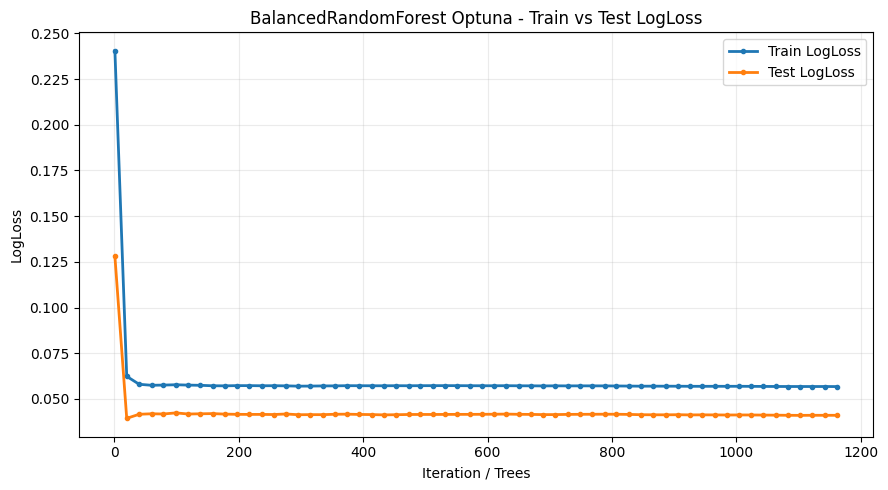

,step,train_loss,test_loss
50,984,0.056932,0.041238
51,1004,0.056944,0.041265
52,1024,0.056910,0.041251
53,1043,0.056869,0.041203
54,1063,0.056842,0.041142
55,1083,0.056824,0.041078
56,1102,0.056820,0.041037
57,1122,0.056812,0.041082
58,1142,0.056826,0.041076
59,1162,0.056785,0.041073


In [12]:
# Dùng sample để plot nhanh hơn, tránh notebook chạy quá nặng
X_train_loss, y_train_loss = sample_xy(X_train, y_train, max_samples=30000)
X_test_loss, y_test_loss = sample_xy(X_test, y_test, max_samples=20000)


def brf_loss_curve(model, X_train_eval, y_train_eval, X_test_eval, y_test_eval, max_points=60):
    checkpoints = set(build_checkpoints(len(model.estimators_), max_points=max_points))
    train_sum = np.zeros(len(y_train_eval), dtype=float)
    test_sum = np.zeros(len(y_test_eval), dtype=float)
    rows = []

    for step, tree in enumerate(model.estimators_, start=1):
        train_sum += tree.predict_proba(X_train_eval)[:, 1]
        test_sum += tree.predict_proba(X_test_eval)[:, 1]

        if step in checkpoints:
            train_prob = np.clip(train_sum / step, 1e-6, 1 - 1e-6)
            test_prob = np.clip(test_sum / step, 1e-6, 1 - 1e-6)
            rows.append({
                "step": step,
                "train_loss": log_loss(y_train_eval, train_prob),
                "test_loss": log_loss(y_test_eval, test_prob),
            })

    return pd.DataFrame(rows)


brf_baseline_loss = brf_loss_curve(brf_model, X_train_loss, y_train_loss, X_test_loss, y_test_loss)
plot_loss_curve(brf_baseline_loss, "BalancedRandomForest Baseline - Train vs Test LogLoss")

brf_optuna_loss = brf_loss_curve(brf_best, X_train_loss, y_train_loss, X_test_loss, y_test_loss)
plot_loss_curve(brf_optuna_loss, "BalancedRandomForest Optuna - Train vs Test LogLoss")


## 8. SHAP Test


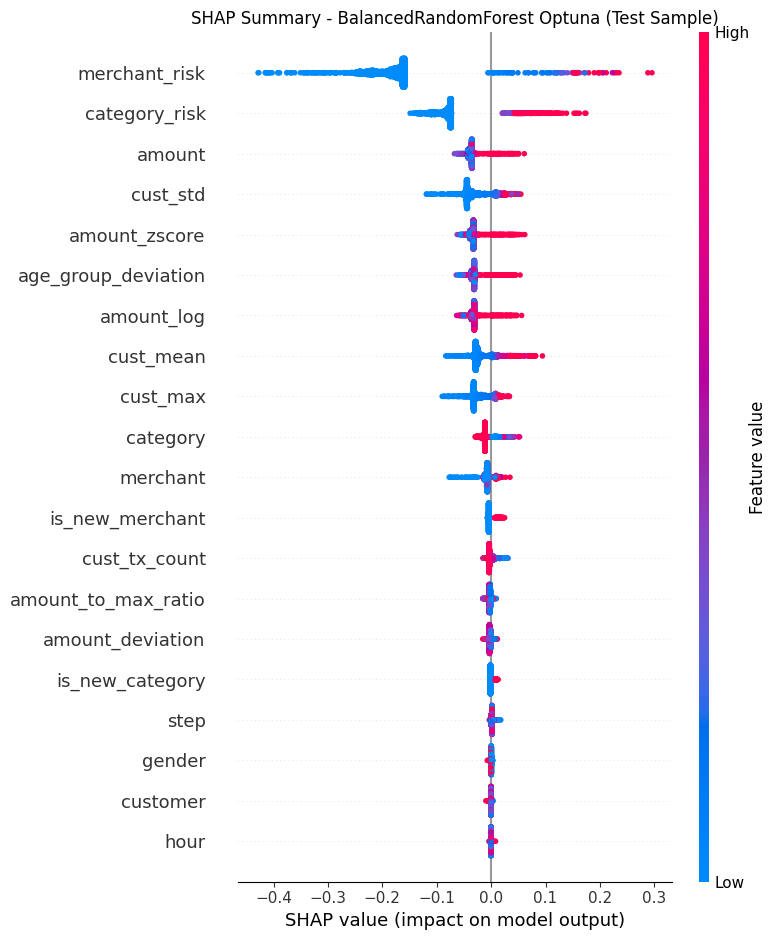

Top 20 features by mean(|SHAP|) - BalancedRandomForest Optuna:


,feature,mean_abs_shap
0,merchant_risk,0.186505
1,category_risk,0.085172
2,amount,0.036981
3,cust_std,0.034911
4,amount_zscore,0.033986
5,age_group_deviation,0.032286
6,amount_log,0.032067
7,cust_mean,0.025162
8,cust_max,0.024322
9,category,0.013667


In [13]:
plot_shap_test(brf_best, X_test, "BalancedRandomForest Optuna")


## 6. Feature Importance

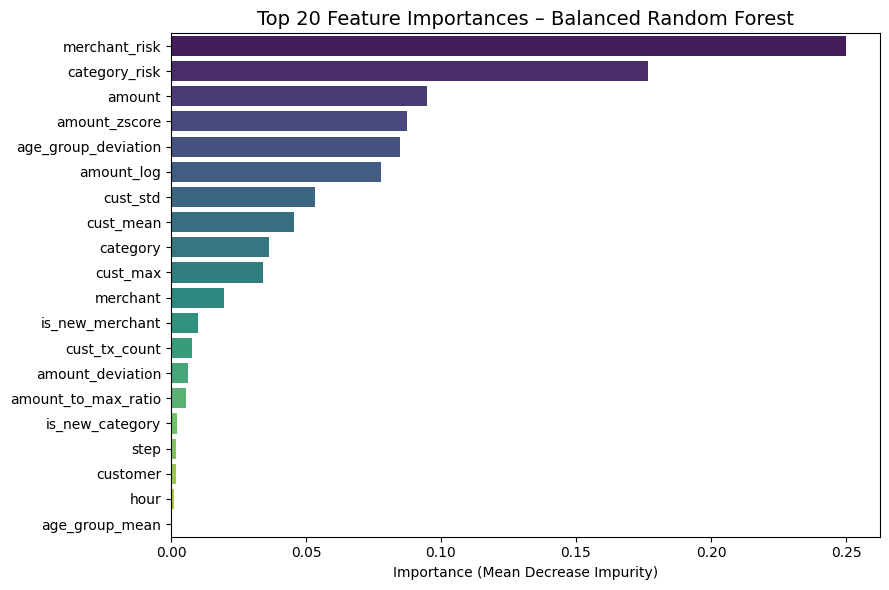


Top 20 features quan trá»ng nháº¥t:
            feature  importance
      merchant_risk    0.250107
      category_risk    0.176705
             amount    0.094721
      amount_zscore    0.087573
age_group_deviation    0.084668
         amount_log    0.077659
           cust_std    0.053233
          cust_mean    0.045647
           category    0.036462
           cust_max    0.034227
           merchant    0.019653
    is_new_merchant    0.009970
      cust_tx_count    0.007878
   amount_deviation    0.006432
amount_to_max_ratio    0.005543
    is_new_category    0.002346
               step    0.002014
           customer    0.001684
               hour    0.001264
     age_group_mean    0.000519


In [14]:
# Lấy feature importance và sắp xếp giảm dần
importance_df = pd.DataFrame({
    'feature':   feature_cols,
    'importance': brf_best.feature_importances_
}).sort_values('importance', ascending=False).reset_index(drop=True)

top_n = 20
top_df = importance_df.head(top_n)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(
    data=top_df, x='importance', y='feature',
    hue='feature', palette='viridis', legend=False, ax=ax
)
ax.set_title(f'Top {top_n} Feature Importances – Balanced Random Forest', fontsize=14)
ax.set_xlabel('Importance (Mean Decrease Impurity)')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

print(f"\nTop {top_n} features quan trá»ng nháº¥t:")
print(top_df.to_string(index=False))

## 7. Lưu mô hình

In [16]:
from pathlib import Path
ROOT = Path("../..").resolve()

DATA_PATH = ROOT / 'src/data/processed'
MODEL_DIR = os.path.abspath(os.path.join(DATA_PATH, '..', 'models'))

os.makedirs(MODEL_DIR, exist_ok=True)
brf_model_path = os.path.join(MODEL_DIR, 'brf_best.pkl')

joblib.dump(brf_best, brf_model_path)
print(f"Catboost model saved to: {brf_model_path}")

Catboost model saved to: D:\AI66A_group_10_Topic_7\src\data\models\brf_best.pkl
